# Generated Cento Stylometry Analysis

This notebook compares the stylistic similarity of **automatically generated centos**
(exact and loose) to both **Vergil** and **Ausonius**, using LambdaG authorship
verification (uncalibrated), and marks the score of the **real cento** (*Cento Nuptialis*)
with a lollipop stick for reference.

Two models are analysed, mirroring the existing stylometry notebooks:

- **Lexical model** (`lexical_model/`): POS-masked sentences (`*_sentences.quesplit.masked.txt`)
- **Metrical lines model** (`metrical_model_lines/`): line-based metrical number-mapped
  sentences (`*.mapped_lines.txt`, N=1 unit hexameter lines)

For each model we produce **four** lollipop plots:

| Set | Candidate |
|-----|-----------|
| exact | Vergil |
| exact | Ausonius |
| loose | Vergil |
| loose | Ausonius |

Each plot shows the distribution of LambdaG scores across all generated centos, with a
lollipop stick marking the real cento's score against the same candidate.

The background corpus (Ovid, Lucan, Silius Italicus, Valerius Flaccus) is used as the
impostor/reference set, exactly as in `cento_stylometry.ipynb` and
`cento_metrical_lines_stylometry.ipynb`.

In [1]:
from __future__ import annotations

import re
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from sentence_corpora import Sentence, TwoLevelCorpus
from sentence_corpora.lambdag import LambdaGAV

## Configuration

All paths are relative to the `stylometry/` working directory (run this notebook from
there, as with the other stylometry notebooks). The score metric used throughout is the
**raw LambdaG score** (`result["score"]`).

In [2]:
# --- Paths ---------------------------------------------------------------
LEXICAL_DIR = Path("lexical_model")
METRICAL_DIR = Path("metrical_model_lines")

# --- LambdaG AV settings -------------------------------------------------
# The generated centos are small (~900 tokens), so use conservative token budgets
# as in the reference notebooks.
KNOWN_TOKENS = 15000
REFERENCE_TOKENS = 30000
ORDER = 8
NUM_REFERENCES = 10
PRIOR = 0.5

# --- Which models / sets / candidates to analyse -------------------------
MODELS = ["lexical", "metrical_lines"]
SETS = ["exact", "loose"]
CANDIDATES = ["vergil", "ausonius"]

# --- How many generated centos to analyse per set -----------------------
# Set to 1000 for the full run, or a smaller number (e.g. 100) for a quick
# visual check.
NUM_ITERATIONS = 1000
SEED = 42

## Load Reference Corpora

For each model we load the candidate corpora (Vergil, Ausonius) and the background
(impostor) corpus into `TwoLevelCorpus` objects. The filename parsing differs between
the two models:

- **lexical**: `vergil_georgics_1_sentences.quesplit.masked.txt` → `(vergil, georgics_1)`
- **metrical_lines**: `vergil_georgics_1.mapped_lines.txt` → `(vergil, georgics_1)`

In [3]:
def parse_lexical_filename(path: Path) -> tuple[str, str]:
    """Parse '<author>_<work>_sentences.quesplit.masked.txt' into (author, work)."""
    name = re.sub(r"_sentences\.quesplit\.masked\.txt$", "", path.name)
    parts = name.split("_", 1)
    if len(parts) != 2:
        raise ValueError(f"Expected '<author>_<work>' in filename, got: {path.name!r}")
    return parts[0], parts[1]


def parse_metrical_filename(path: Path) -> tuple[str, str]:
    """Parse '<author>_<work>.mapped_lines.txt' into (author, work)."""
    name = re.sub(r"\.mapped_lines\.txt$", "", path.name)
    parts = name.split("_", 1)
    if len(parts) == 1:
        return parts[0], ""
    return parts[0], parts[1]


def load_lexical_corpus(data_dir: Path) -> TwoLevelCorpus:
    """Read all *_sentences.quesplit.masked.txt files into a TwoLevelCorpus."""
    sentences = []
    for path in sorted(data_dir.glob("*_sentences.quesplit.masked.txt")):
        author, work = parse_lexical_filename(path)
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    sentences.append(Sentence(text=line, metadata={"author": author, "work": work}))
    return TwoLevelCorpus(sentences, levels=["author", "work"])


def load_metrical_corpus(data_dir: Path) -> TwoLevelCorpus:
    """Read all *.mapped_lines.txt files into a TwoLevelCorpus."""
    sentences = []
    for path in sorted(data_dir.glob("*.mapped_lines.txt")):
        author, work = parse_metrical_filename(path)
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    sentences.append(Sentence(text=line, metadata={"author": author, "work": work}))
    return TwoLevelCorpus(sentences, levels=["author", "work"])


def load_corpus(model: str, data_dir: Path) -> TwoLevelCorpus:
    """Dispatch to the correct loader for the given model."""
    if model == "lexical":
        return load_lexical_corpus(data_dir)
    if model == "metrical_lines":
        return load_metrical_corpus(data_dir)
    raise ValueError(f"Unknown model: {model!r}")


def corpus_stats(corpus: TwoLevelCorpus, label: str) -> None:
    print(f"{label}: {len(corpus)} sentences, {sum(len(s.text.split()) for s in corpus)} tokens")


# Load reference corpora for both models
reference = {}
for model in MODELS:
    base = LEXICAL_DIR if model == "lexical" else METRICAL_DIR
    reference[model] = {
        "vergil": load_corpus(model, base / "vergil"),
        "ausonius": load_corpus(model, base / "ausonius"),
        "background": load_corpus(model, base / "background"),
    }
    print(f"\n[{model}]")
    corpus_stats(reference[model]["vergil"], "  Vergil")
    corpus_stats(reference[model]["ausonius"], "  Ausonius")
    corpus_stats(reference[model]["background"], "  Background")


[lexical]
  Vergil: 809 sentences, 17802 tokens
  Ausonius: 959 sentences, 17776 tokens
  Background: 15111 sentences, 306869 tokens

[metrical_lines]
  Vergil: 2187 sentences, 16360 tokens
  Ausonius: 2247 sentences, 16396 tokens
  Background: 37840 sentences, 280477 tokens


## Load the Real Cento (Question Corpus)

The real cento is the *Cento Nuptialis* question text. Its score against each candidate
becomes the **lollipop marker** on each plot.

In [4]:
def load_single_file_corpus(path: Path, author: str, work: str) -> TwoLevelCorpus:
    """Load a single file's lines into a TwoLevelCorpus."""
    sentences = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                sentences.append(Sentence(text=line, metadata={"author": author, "work": work}))
    return TwoLevelCorpus(sentences, levels=["author", "work"])


real_cento = {}
for model in MODELS:
    if model == "lexical":
        path = LEXICAL_DIR / "question" / "cento_nuptialis_sentences.quesplit.masked.txt"
    else:
        path = METRICAL_DIR / "question" / "cento_nuptialis.mapped_lines.txt"
    real_cento[model] = load_single_file_corpus(path, "cento", "nuptialis")
    corpus_stats(real_cento[model], f"[{model}] Real cento (question)")

[lexical] Real cento (question): 58 sentences, 1079 tokens
[metrical_lines] Real cento (question): 131 sentences, 955 tokens


## Load Generated Centos

Each generated cento is stored as its own file (`cento_XXXX...`). We load each one as a
separate corpus so we can score it individually. The cento index is parsed from the
filename.

In [5]:
def load_generated_centos(model: str, set_name: str, limit: int | None = None) -> dict[int, TwoLevelCorpus]:
    """Load generated centos for a (model, set) into {index: corpus}.

    Args:
        model: Model name ("lexical" or "metrical_lines").
        set_name: Set name ("exact" or "loose").
        limit: Maximum number of centos to load. If None, load all.
    """
    base = LEXICAL_DIR if model == "lexical" else METRICAL_DIR
    data_dir = base / f"generated_{set_name}"

    if model == "lexical":
        pattern = "cento_*_sentences.quesplit.masked.txt"
        index_re = re.compile(r"cento_(\d+)_sentences\.quesplit\.masked\.txt$")
    else:
        pattern = "cento_*.mapped_lines.txt"
        index_re = re.compile(r"cento_(\d+)\.mapped_lines\.txt$")

    centos = {}
    for path in sorted(data_dir.glob(pattern)):
        if limit is not None and len(centos) >= limit:
            break
        m = index_re.search(path.name)
        if not m:
            continue
        idx = int(m.group(1))
        centos[idx] = load_single_file_corpus(path, "cento", f"generated_{idx}")
    return centos


generated = {}
for model in MODELS:
    generated[model] = {}
    for set_name in SETS:
        centos = load_generated_centos(model, set_name, limit=NUM_ITERATIONS)
        generated[model][set_name] = centos
        n_tokens = sum(sum(len(s.text.split()) for s in c) for c in centos.values())
        print(f"[{model}] generated_{set_name}: {len(centos)} centos, {n_tokens} total tokens")

[lexical] generated_exact: 1000 centos, 1076973 total tokens
[lexical] generated_loose: 1000 centos, 1078596 total tokens
[metrical_lines] generated_exact: 1000 centos, 986161 total tokens
[metrical_lines] generated_loose: 1000 centos, 986612 total tokens


## Run LambdaG AV — Real Cento (Lollipop Markers)

Score the real cento against each candidate (with background impostors) for both models.
These scores are the lollipop markers.

In [6]:
def run_av(known_entity: str, q_corpus: TwoLevelCorpus, kr_corpus: TwoLevelCorpus,
           rng: np.random.Generator) -> dict[str, Any]:
    """Run a single LambdaG AV problem and return the raw result dict."""
    av = LambdaGAV()
    return av.run_single_av_problem(
        known_entity=known_entity,
        q_corpus=q_corpus,
        kr_corpus=kr_corpus,
        known_tokens=KNOWN_TOKENS,
        reference_tokens=REFERENCE_TOKENS,
        order=ORDER,
        num_references=NUM_REFERENCES,
        rng=rng,
    )


def make_kr_corpus(candidate_corpus: TwoLevelCorpus, background_corpus: TwoLevelCorpus) -> TwoLevelCorpus:
    """Combine a candidate corpus with the background impostor corpus."""
    kr_sentences = list(candidate_corpus) + list(background_corpus)
    return TwoLevelCorpus(kr_sentences, levels=["author", "work"])


# Score the real cento against each candidate for both models
real_scores = {}
for model in MODELS:
    real_scores[model] = {}
    for candidate in CANDIDATES:
        kr = make_kr_corpus(reference[model][candidate], reference[model]["background"])
        rng = np.random.default_rng(SEED)
        result = run_av(candidate, real_cento[model], kr, rng)
        real_scores[model][candidate] = result.get("score", 0.0)
        print(f"[{model}] Real cento vs {candidate}: score={real_scores[model][candidate]:.4f}")

[lexical] Real cento vs vergil: score=99.5086
[lexical] Real cento vs ausonius: score=-16.7861
[metrical_lines] Real cento vs vergil: score=116.1504
[metrical_lines] Real cento vs ausonius: score=-44.8310


## Run LambdaG AV — Generated Centos

Score every generated cento against each candidate (with background impostors) for both
models. This is the expensive step: `2 models × 2 sets × NUM_ITERATIONS centos × 2 candidates`
AV runs. We parallelise with Ray, exactly as in the reference notebooks.

In [7]:
import ray
from tqdm import tqdm


# Build the KR corpora ONCE (per model × candidate) and store them as module-level
# globals. The remote function below references them by closure, so Ray serialises
# each corpus a single time per worker and caches it — instead of shipping the
# (large) KR corpus with every one of the ~4000 tasks.
KR_CORPORA: dict[tuple[str, str], TwoLevelCorpus] = {}
for model in MODELS:
    for candidate in CANDIDATES:
        KR_CORPORA[(model, candidate)] = make_kr_corpus(
            reference[model][candidate], reference[model]["background"]
        )


@ray.remote
def run_generated_iteration(model: str, set_name: str, idx: int, candidate: str,
                            q_texts: list[str], seed: int) -> dict[str, Any]:
    """Run a single generated-cento AV iteration inside a Ray worker.

    The KR corpus is captured by closure from the module-level ``KR_CORPORA``
    dict (serialised once per worker), so we only ship the small question text
    per task.
    """
    iter_rng = np.random.default_rng(seed)

    q_sentences = [Sentence(text=t, metadata={"author": "cento", "work": f"generated_{idx}"})
                   for t in q_texts]
    q_corpus = TwoLevelCorpus(q_sentences, levels=["author", "work"])

    kr_corpus = KR_CORPORA[(model, candidate)]

    av = LambdaGAV()
    result = av.run_single_av_problem(
        known_entity=candidate,
        q_corpus=q_corpus,
        kr_corpus=kr_corpus,
        known_tokens=KNOWN_TOKENS,
        reference_tokens=REFERENCE_TOKENS,
        order=ORDER,
        num_references=NUM_REFERENCES,
        rng=iter_rng,
    )

    return {
        "model": model,
        "set": set_name,
        "index": idx,
        "candidate": candidate,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "q_tokens": result.get("unknown_tokens_used", 0),
        "error": result.get("error", None),
    }


def corpus_to_texts(corpus: TwoLevelCorpus) -> list[str]:
    return [s.text for s in corpus]


ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

tasks = []
for model in MODELS:
    for set_name in SETS:
        for idx, q_corpus in generated[model][set_name].items():
            q_texts = corpus_to_texts(q_corpus)
            for candidate in CANDIDATES:
                seed = SEED + idx
                tasks.append(run_generated_iteration.remote(
                    model, set_name, idx, candidate, q_texts, seed,
                ))

print(f"Submitting {len(tasks)} AV tasks...")
generated_results = []
for _ in tqdm(range(len(tasks)), desc="Generated cento AV"):
    ready, tasks = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    generated_results.append(result)

ray.shutdown()
print("\nDone.")

2026-08-10 16:47:10,532	INFO worker.py:2024 -- Started a local Ray instance.


Ray initialized with 10.0 CPUs
Submitting 8000 AV tasks...


Generated cento AV: 100%|██████████| 8000/8000 [3:52:38<00:00,  1.74s/it]     



Done.


## Results Table

Assemble all generated-cento scores into a tidy DataFrame.

In [8]:
df = pd.DataFrame(generated_results)
df = df.dropna(subset=["score"])
df["score"] = df["score"].astype(float)

# Add the real cento scores as a separate lookup
real_df = pd.DataFrame([
    {"model": model, "candidate": candidate, "real_score": score}
    for model, cands in real_scores.items()
    for candidate, score in cands.items()
])

print(f"Total generated-cento AV results: {len(df)}")
print(f"Real cento scores:\n{real_df.to_string(index=False)}")

# Quick summary per (model, set, candidate)
summary = (
    df.groupby(["model", "set", "candidate"])["score"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
)
print("\nGenerated cento score summary:")
print(summary.to_string())

Total generated-cento AV results: 8000
Real cento scores:
         model candidate  real_score
       lexical    vergil   99.508572
       lexical  ausonius  -16.786091
metrical_lines    vergil  116.150444
metrical_lines  ausonius  -44.831035

Generated cento score summary:
                                count      mean      std       min       max
model          set   candidate                                              
lexical        exact ausonius    1000  -85.7828  49.0417 -245.2554   67.7821
                     vergil      1000  202.1768  80.8094   -6.4996  470.3320
               loose ausonius    1000  -86.2632  49.7113 -246.4592   75.9173
                     vergil      1000  217.4252  86.9332  -32.4921  541.2840
metrical_lines exact ausonius    1000  -51.8533  56.6144 -240.7547  117.5921
                     vergil      1000  175.1219  55.6591   12.5524  335.4310
               loose ausonius    1000  -55.9011  55.2103 -230.9455  105.8549
                     vergil     

In [ ]:
# df.to_pickle("generated_stylometry_df.pkl")
# df = pd.read_pickle("generated_stylometry_df.pkl")

## Visualisation

For each (model, set) we plot the distribution of generated-cento scores against each
candidate (Vergil, Ausonius) as a **histogram + rugplot**, with the **real cento** score
marked by a lollipop stick (a red dashed vertical line with a dot on top).

This mirrors the style of `cento_syntactic_stylometry.ipynb` (histogram + rugplot with
a red cento marker).

Font name: `Roboto Condensed`


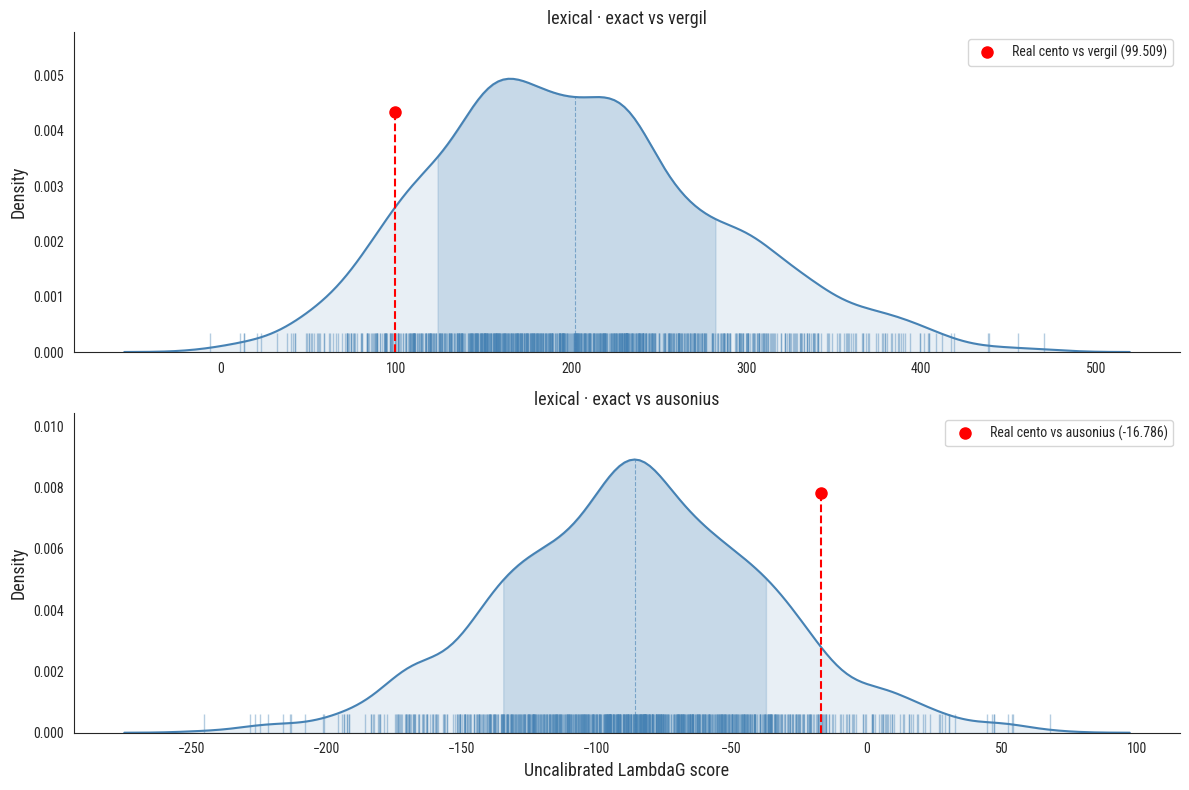

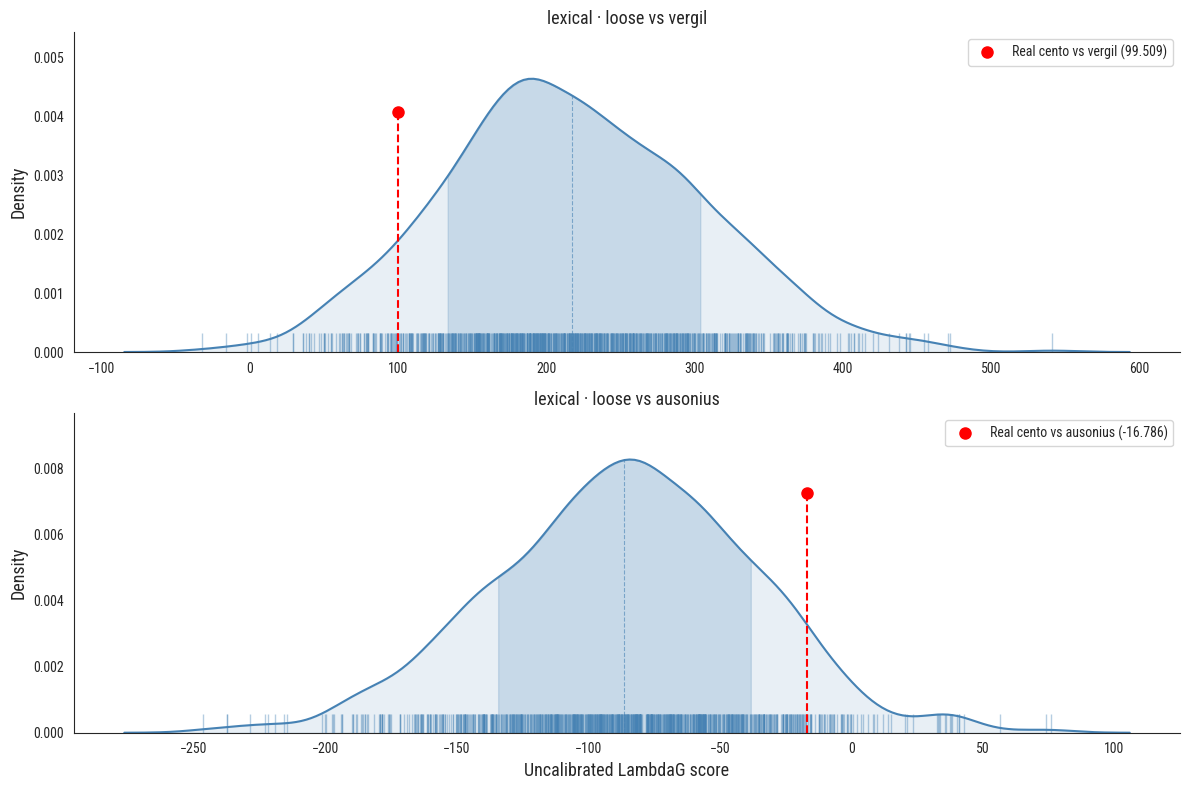

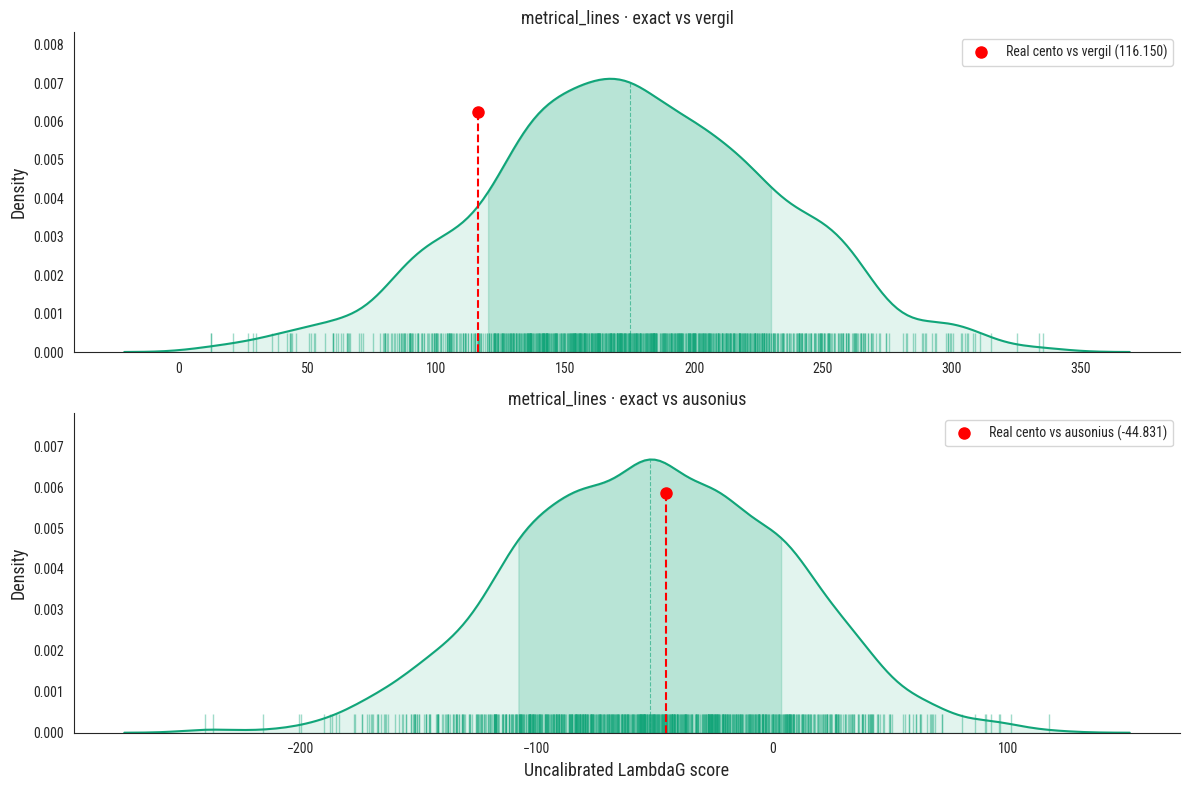

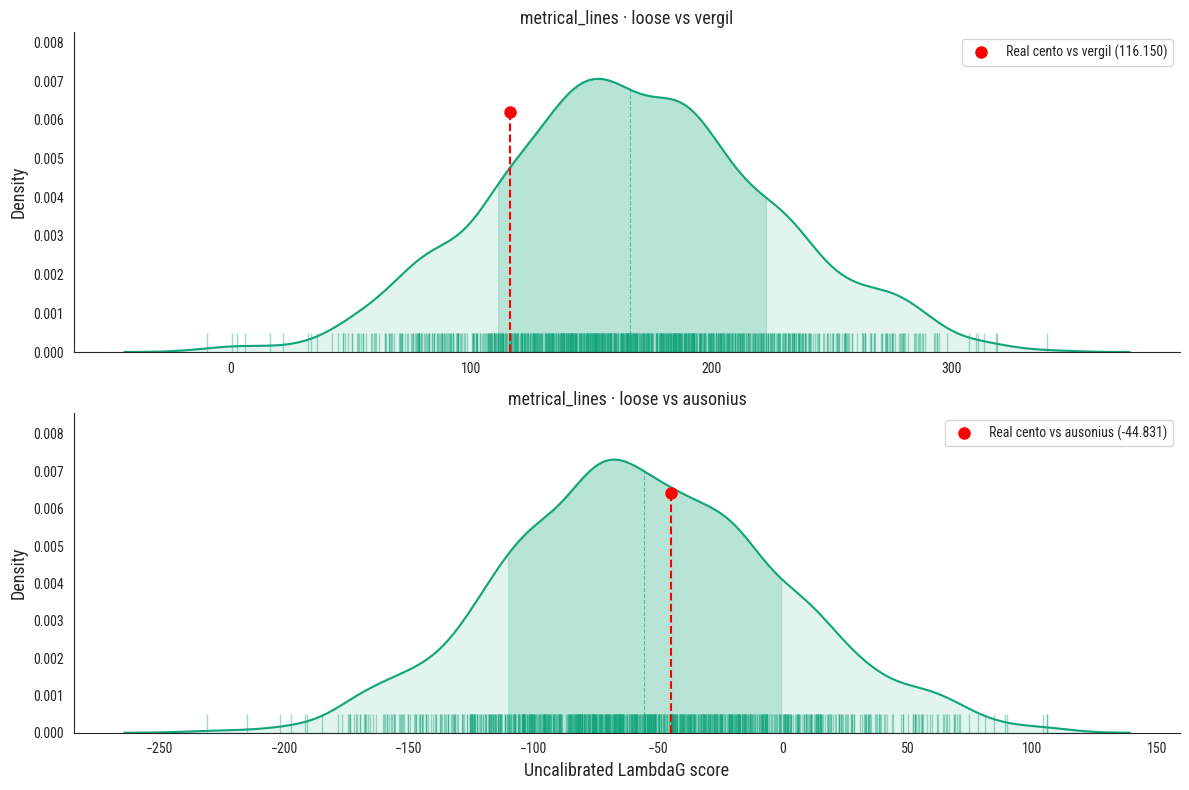

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import mpl_fontkit as fk

fk.install("Roboto Condensed")
sns.set_style("white")

plt.rcParams["font.family"] = "Roboto Condensed"

# Colour per model: steelblue for lexical, green (#11A579FF) for metrical
MODEL_COLORS = {"lexical": "steelblue", "metrical_lines": "#11A579FF"}


def plot_baseline(ax, data, cento_score, title, candidate, color, xlabel=""):
    scores = data["score"]
    mean = scores.mean()
    sd = scores.std()

    # KDE as a line (no fill) so we can extract coordinates
    sns.kdeplot(data=data, x="score", ax=ax, color=color,
                linewidth=1.5, fill=False, bw_adjust=0.8)
    sns.rugplot(data=data, x="score", ax=ax, color=color,
                alpha=0.4, height=0.06)

    # Extract curve coordinates
    line = ax.lines[0]
    x_data, y_data = line.get_data()

    # Fill the curve manually
    ax.fill_between(x_data, y_data, alpha=0.12, color=color)

    # Shade ±1 SD region
    mask = (np.array(x_data) >= mean - sd) & (np.array(x_data) <= mean + sd)
    ax.fill_between(np.array(x_data)[mask], np.array(y_data)[mask],
                    alpha=0.2, color=color)

    # Mean dashed line — stops at curve height
    mean_y = float(np.interp(mean, x_data, y_data))
    ax.vlines(mean, 0, mean_y, colors=color, linewidth=0.8,
              linestyles="--", alpha=0.6)

    # Cento lollipop marker
    ax.axvline(cento_score, ymax=0.75, color="red", linewidth=1.5, linestyle="--")
    cento_y = ax.get_ylim()[1] * 0.75
    ax.plot(cento_score, cento_y, "o", color="red", markersize=8,
            label=f"Real cento vs {candidate} ({cento_score:.3f})")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel(ax.get_ylabel(), fontsize=13)
    ax.legend(fontsize=10, loc="upper right")
    sns.despine(ax=ax)


# Generate the 4 figures (2 models × 2 sets), each with Vergil & Ausonius panels
for model in MODELS:
    for set_name in SETS:
        color = MODEL_COLORS[model]
        fig, axes = plt.subplots(2, 1, figsize=(12, 8))

        for ax, candidate in zip(axes, CANDIDATES):
            sub = df[(df["model"] == model) & (df["set"] == set_name) & (df["candidate"] == candidate)]
            real_score = real_scores[model][candidate]

            title = f"{model} · {set_name} vs {candidate}"
            xlabel = "Uncalibrated LambdaG score" if candidate == CANDIDATES[-1] else ""
            plot_baseline(ax, sub, real_score, title, candidate, color, xlabel=xlabel)

        plt.tight_layout()
        plt.show()
